In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.pipeline import Pipeline

In [2]:
train_df = pd.read_csv(
  "../data/processed/raw/train.csv"
)

validation_df = pd.read_csv(
  "../data/processed/raw/validation.csv"
)

In [3]:
print("Train shape: ", train_df.shape)
print("Validation shape: ", validation_df.shape)

train_df.head()

Train shape:  (18831, 8)
Validation shape:  (4010, 8)


,flags,instruction,category,intent,response,normalized_instruction,processed_instruction,split
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...,question about cancelling order {{order number}},question about cancelling order {{Order Number}},train
1,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...,i need help cancelling puchase {{order number}},i need help cancelling puchase {{Order Number}},train
2,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...,i need to cancel purchase {{order number}},I need to cancel purchase {{Order Number}},train
3,BI,can you help me cancel order {{Order Number}}?,ORDER,cancel_order,"Of course, I'm here to assist you in canceling...",can you help me cancel order {{order number}}?,can you help me cancel order {{Order Number}}?,train
4,BCLN,"I can no longer afford order {{Order Number}},...",ORDER,cancel_order,I pick up what you're putting down that you're...,"i can no longer afford order {{order number}},...","I can no longer afford order {{Order Number}},...",train


In [4]:
X_train = train_df['processed_instruction']
y_train = train_df["intent"]

X_val = validation_df['processed_instruction']
y_val = validation_df['intent']

print("Training samples: ", len(X_train))
print("Validation samples: ", len(X_val))

Training samples:  18831
Validation samples:  4010


### Base Pipeline

In [5]:
baseline_pipeline = Pipeline([
  (
    "tfidf",
    TfidfVectorizer(
      lowercase=True
    )
  ),
  (
    "classifier",
    LogisticRegression(
      max_iter=1000,
      random_state = 42
    )
  )
])

In [6]:
# Train

baseline_pipeline.fit(
  X_train,
  y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](27,)","['cancel_order','change_order','change_shipping_address',..., 'switch_account','track_order','track_refund']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


### Validation Prediction

In [7]:
y_val_pred = baseline_pipeline.predict(
  X_val
)

#### Compute Metrics

In [8]:
accuracy = accuracy_score(
  y_val,
  y_val_pred
)

macro_precision = precision_score(
  y_val,
  y_val_pred,
  average='macro'
)

macro_recall = recall_score(
  y_val,
  y_val_pred,
  average='macro'
)

macro_f1 = f1_score(
  y_val,
  y_val_pred,
  average='macro'
)

weighted_f1 = f1_score(
  y_val,
  y_val_pred,
  average="weighted"
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:   {macro_recall:.4f}")
print(f"Macro F1:   {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")

Accuracy:  0.9955
Macro Precision:  0.9956
Macro Recall:   0.9956
Macro F1:   0.9956
Weighted F1:  0.9955


### Classification Report

In [9]:
print(
  classification_report(
    y_val,
    y_val_pred,
    digits=4
  )
)

                          precision    recall  f1-score   support

            cancel_order     1.0000    0.9795    0.9896       146
            change_order     0.9739    0.9868    0.9803       151
 change_shipping_address     0.9932    1.0000    0.9966       147
  check_cancellation_fee     1.0000    1.0000    1.0000       142
           check_invoice     1.0000    0.9933    0.9967       150
   check_payment_methods     1.0000    1.0000    1.0000       150
     check_refund_policy     1.0000    1.0000    1.0000       150
               complaint     0.9933    1.0000    0.9967       149
contact_customer_service     1.0000    0.9933    0.9966       149
     contact_human_agent     0.9934    1.0000    0.9967       150
          create_account     1.0000    0.9750    0.9873       160
          delete_account     0.9803    1.0000    0.9900       149
        delivery_options     1.0000    1.0000    1.0000       138
         delivery_period     1.0000    1.0000    1.0000       149
         

### Confusion Matrix

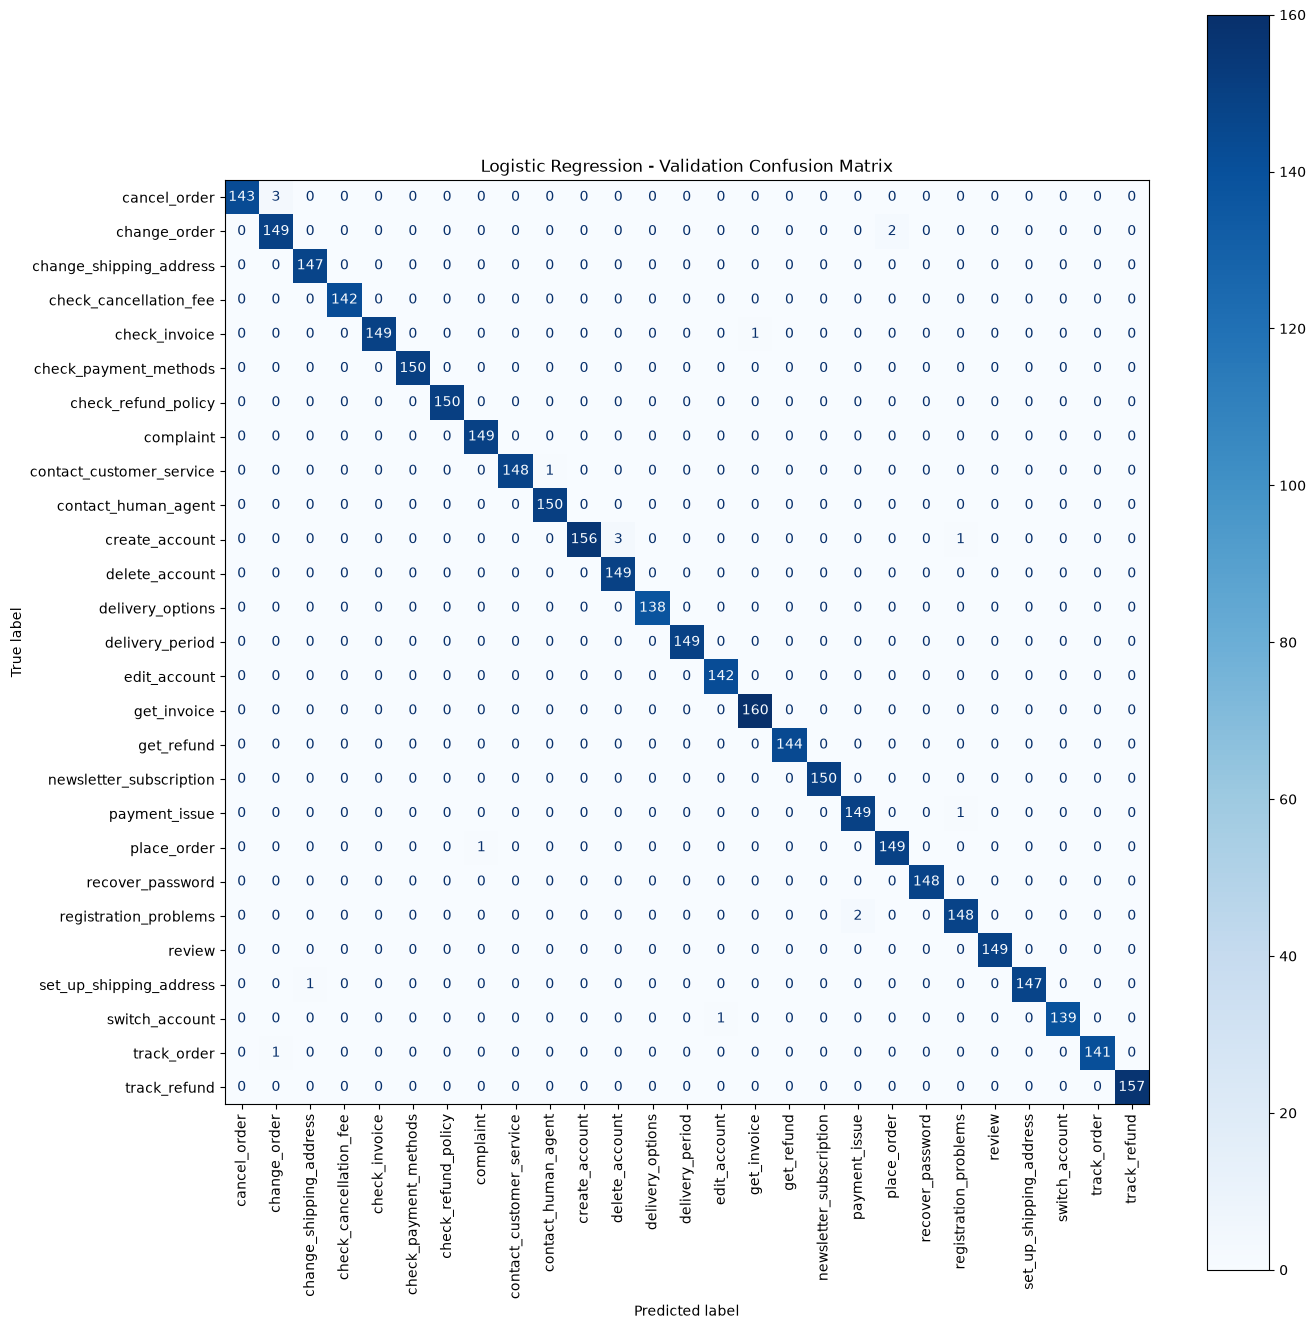

In [10]:
fig, ax = plt.subplots(
  figsize=(14, 14)
)

ConfusionMatrixDisplay.from_predictions(
  y_val,
  y_val_pred,
  xticks_rotation=90,
  ax=ax,
  cmap="Blues"
)

plt.title(
  "Logistic Regression - Validation Confusion Matrix"
)

plt.tight_layout()

plt.show()

### Build a dataframe of validation predictions

In [11]:
results_df = validation_df.copy()

results_df['predicted_intent'] = y_val_pred

results_df['is_correct'] = (
  results_df["intent"] == results_df['predicted_intent']
)

print("Correct predictions: ")
print(results_df["is_correct"].value_counts())

print(
  "\nNumber of errors: ",
  (~results_df["is_correct"]).sum()
)

Correct predictions: 
is_correct
True     3992
False      18
Name: count, dtype: int64

Number of errors:  18


### Inspect all misclassified examples

In [12]:
errors_df = results_df[
  ~results_df["is_correct"]
].copy()

errors_df[
  [
    "instruction",
    "intent",
    "predicted_intent",
    "category",
    "flags"
  ]
]

,instruction,intent,predicted_intent,category,flags
10,how could icancel purchase {{Order Number}},cancel_order,change_order,ORDER,BILPQZ
98,problem with cancelig order {{Order Number}},cancel_order,change_order,ORDER,BZ
135,need assistance cancelinv purchase {{Order Num...,cancel_order,change_order,ORDER,BLQZ
183,i nmeed assistance removing some products,change_order,place_order,ORDER,BLMQZ
256,hep changing some products of an order,change_order,place_order,ORDER,BLMZ
600,i have to check bill #37777 can i get some help,check_invoice,get_invoice,INVOICE,BCILQ
1270,I need help contacting customerservice,contact_customer_service,contact_human_agent,CONTACT,BZ
1546,"I don't have a platinum account, can I sign up?",create_account,registration_problems,ACCOUNT,BCILNZ
1565,I want a pro account,create_account,delete_account,ACCOUNT,BLZ
1593,is it possible to crewate a gold account,create_account,delete_account,ACCOUNT,BILQZ


### Count Confusion Pairs

In [13]:
confusion_pairs = (
  errors_df
  .groupby(
    ["intent", "predicted_intent"]
  )
  .size()
  .reset_index(name="count")
  .sort_values(
    "count",
    ascending=False
  )
)

confusion_pairs

,intent,predicted_intent,count
0,cancel_order,change_order,3
4,create_account,delete_account,3
8,registration_problems,payment_issue,2
1,change_order,place_order,2
3,contact_customer_service,contact_human_agent,1
2,check_invoice,get_invoice,1
6,payment_issue,registration_problems,1
5,create_account,registration_problems,1
7,place_order,complaint,1
9,set_up_shipping_address,change_shipping_address,1


### Inspect Model Confidence

In [14]:
val_probabilities = (
    baseline_pipeline.predict_proba(
        X_val
    )
)

results_df["prediction_confidence"] = (
    val_probabilities.max(axis=1)
)

In [15]:
errors_df = results_df[
    ~results_df["is_correct"]
].copy()

In [16]:
errors_df[
  [
    "instruction",
    "intent",
    "predicted_intent",
    "prediction_confidence"
  ]
].sort_values(
  "prediction_confidence",
  ascending=False
)

,instruction,intent,predicted_intent,prediction_confidence
3532,I have troubles submittng the shipping address,set_up_shipping_address,change_shipping_address,0.773020
1602,how can I find information about openinga pro ...,create_account,delete_account,0.679333
10,how could icancel purchase {{Order Number}},cancel_order,change_order,0.551212
98,problem with cancelig order {{Order Number}},cancel_order,change_order,0.546377
3175,I do not know how I can inform of problems wit...,registration_problems,payment_issue,0.472248
256,hep changing some products of an order,change_order,place_order,0.465047
1565,I want a pro account,create_account,delete_account,0.454897
600,i have to check bill #37777 can i get some help,check_invoice,get_invoice,0.439561
3151,need help reporting errors with registratons,registration_problems,payment_issue,0.418019
183,i nmeed assistance removing some products,change_order,place_order,0.411494


#### For each validation sample, retrieve the model's top two predicted intents

In [17]:
import numpy as np

classes = (
  baseline_pipeline
  .named_steps["classifier"]
  .classes_
)

top_2_indices = np.argsort(
  val_probabilities,
  axis=1
)[:, -2:][:, ::-1]

results_df["top_1_intent"] = (
  classes[top_2_indices[:, 0]]
)

results_df['top_2_intent'] = (
  classes[top_2_indices[:, 1]]
)

results_df["top_1_probability"] = (
  val_probabilities[
    np.arange(len(val_probabilities)),
    top_2_indices[:, 0]
  ]
)

results_df["top_2_probability"] = (
  val_probabilities[
    np.arange(len(val_probabilities)),
    top_2_indices[:, 1]
  ]
)

In [18]:
errors_df = results_df[
  ~results_df["is_correct"]
].copy()

errors_df[
  [
    "instruction",
    "intent",
    "top_1_intent",
    "top_1_probability",
    "top_2_intent",
    "top_2_probability"
  ]
]

,instruction,intent,top_1_intent,top_1_probability,top_2_intent,top_2_probability
10,how could icancel purchase {{Order Number}},cancel_order,change_order,0.551212,track_order,0.233703
98,problem with cancelig order {{Order Number}},cancel_order,change_order,0.546377,cancel_order,0.327098
135,need assistance cancelinv purchase {{Order Num...,cancel_order,change_order,0.392003,cancel_order,0.390302
183,i nmeed assistance removing some products,change_order,place_order,0.411494,review,0.093872
256,hep changing some products of an order,change_order,place_order,0.465047,change_order,0.323753
600,i have to check bill #37777 can i get some help,check_invoice,get_invoice,0.439561,check_invoice,0.341373
1270,I need help contacting customerservice,contact_customer_service,contact_human_agent,0.189698,place_order,0.067489
1546,"I don't have a platinum account, can I sign up?",create_account,registration_problems,0.311853,create_account,0.263495
1565,I want a pro account,create_account,delete_account,0.454897,create_account,0.354282
1593,is it possible to crewate a gold account,create_account,delete_account,0.408195,switch_account,0.152142


### Check errors by linguistic flag

In [19]:
important_flags = ["Z", "Q", "K", "P", "N"]

for flag in important_flags:
  mask = errors_df["flags"].str.contains(
    flag,
    na=False
  )

  print(
    f"{flag}: {mask.sum()}"
    f" misclassified samples"
  )

Z: 16 misclassified samples
Q: 9 misclassified samples
K: 1 misclassified samples
P: 1 misclassified samples
N: 1 misclassified samples


### Calculate error rate per flag

In [20]:
for flag in important_flags:

  flag_mask = validation_df[
    "flags"
  ].str.contains(
    flag,
    na=False
  )

  flag_results = results_df[
    flag_mask
  ]

  error_rate = (
    (~flag_results["is_correct"]).mean()
    *100
  )

  print(
    f"{flag}: "
    f"{len(flag_results)} samples, "
    f"{error_rate:.2f}% error rate"
  )

Z: 765 samples, 2.09% error rate
Q: 1373 samples, 0.66% error rate
K: 329 samples, 0.30% error rate
P: 201 samples, 0.50% error rate
N: 88 samples, 1.14% error rate


### Look at some correct-but-low-confidence examples

In [21]:
low_confidence_correct = (
  results_df[
    results_df["is_correct"]
  ]
  .sort_values(
    "prediction_confidence"
  )
  .head(20)
)

low_confidence_correct[
  [
    "instruction",
    "intent",
    "predicted_intent",
    "prediction_confidence"
  ]
]

,instruction,intent,predicted_intent,prediction_confidence
370,i dont know what i need to do to correct thead...,change_shipping_address,change_shipping_address,0.103643
3759,where do I check my last purchase estimated ti...,track_order,track_order,0.132008
3658,I am trying to change user,switch_account,switch_account,0.163413
941,are service charges reimbursable?,check_refund_policy,check_refund_policy,0.199077
2832,what do I have to do to order somethingh?,place_order,place_order,0.202620
1785,is it possible to remove the standardaccount?,delete_account,delete_account,0.219307
1675,have a question about the termination of a Fre...,delete_account,delete_account,0.232021
1473,is it possible to speakto a person?,contact_human_agent,contact_human_agent,0.238147
1831,do ya ship toHungary,delivery_options,delivery_options,0.240709
1834,do ya ship toMexico,delivery_options,delivery_options,0.240709


### Evaluation Function

In [22]:
def evaluate_placeholder_strategy(strategy):

  train_df = pd.read_csv(
    f"../data/processed/{strategy}/train.csv"
  )

  validation_df = pd.read_csv(
    f"../data/processed/{strategy}/validation.csv"
  )

  X_train = train_df["processed_instruction"]
  y_train = train_df['intent']

  X_val = validation_df['processed_instruction']
  y_val = validation_df['intent']

  pipeline = Pipeline([
    (
      "tfidf",
      TfidfVectorizer(
        lowercase=True
      )
    ),
    (
      'classifier',
      LogisticRegression(
        max_iter=1000,
        random_state=42
      )
    )
  ])

  pipeline.fit(
    X_train,
    y_train
  )

  predictions = pipeline.predict(
    X_val
  )

  return{
    "strategy": strategy,
    "accuracy": accuracy_score(
      y_val,
      predictions
    ),
    "macro_f1": f1_score(
      y_val,
      predictions,
      average="macro"
    ),
    "weighted_f1": f1_score(
      y_val,
      predictions,
      average="weighted"
    ),
    "errors": (
      predictions != y_val
    ).sum(),
    "features": len(
      pipeline
      .named_steps["tfidf"]
      .vocabulary_
    )
  }

In [23]:
strategies = [
    "raw",
    "generic",
    "remove"
]

ablation_results = []

for strategy in strategies:
    result = evaluate_placeholder_strategy(
        strategy
    )

    ablation_results.append(result)

ablation_df = pd.DataFrame(
    ablation_results
)

ablation_df

,strategy,accuracy,macro_f1,weighted_f1,errors,features
0,raw,0.995511,0.995559,0.995512,18,2305
1,generic,0.989027,0.988863,0.989010,44,2302
2,remove,0.988778,0.988456,0.988699,45,2297


### Placeholder Ablation Findings

- The raw-placeholder Logistic Regression baseline achieved approximately
  99.55% validation accuracy with 18 errors.

- Replacing all placeholder types with a generic `ENTITY_TOKEN` reduced
  accuracy to approximately 98.90% and increased errors to 44.

- Removing placeholders entirely produced nearly identical performance
  (approximately 98.88%, 45 errors).

- The similarity between the generic and removal strategies suggests that
  the model benefits primarily from the semantic identity of synthetic
  placeholders such as `Order Number`, `Refund Amount`, or `Delivery City`,
  rather than simply from the presence of an entity.

- Despite removing this shortcut signal, validation accuracy remains close
  to 99%, indicating that the dataset's intent classes are highly
  lexically separable.

## Linear SVM

In [24]:
from sklearn.svm import LinearSVC

#### Load generic data

In [25]:
generic_train_df = pd.read_csv(
    "../data/processed/generic/train.csv"
)

generic_val_df = pd.read_csv(
    "../data/processed/generic/validation.csv"
)

X_train_generic = generic_train_df[
    "processed_instruction"
]

y_train_generic = generic_train_df[
    "intent"
]

X_val_generic = generic_val_df[
    "processed_instruction"
]

y_val_generic = generic_val_df[
    "intent"
]

#### SVM Pipeline

In [26]:
svm_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True
        )
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

svm_pipeline.fit(
    X_train_generic,
    y_train_generic
)

svm_predictions = svm_pipeline.predict(
    X_val_generic
)

#### Calculate metrics

In [27]:
svm_accuracy = accuracy_score(
    y_val_generic,
    svm_predictions
)

svm_macro_f1 = f1_score(
    y_val_generic,
    svm_predictions,
    average="macro"
)

svm_weighted_f1 = f1_score(
    y_val_generic,
    svm_predictions,
    average="weighted"
)

svm_errors = (
    svm_predictions != y_val_generic
).sum()

print(
    f"Accuracy:    {svm_accuracy:.4f}"
)

print(
    f"Macro F1:    {svm_macro_f1:.4f}"
)

print(
    f"Weighted F1: {svm_weighted_f1:.4f}"
)

print(
    f"Errors:      {svm_errors}"
)

Accuracy:    0.9903
Macro F1:    0.9900
Weighted F1: 0.9902
Errors:      39


### Comparison 

In [28]:
model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "strategy": "generic",
        "accuracy": ablation_df.loc[
            ablation_df["strategy"] == "generic",
            "accuracy"
        ].iloc[0],
        "macro_f1": ablation_df.loc[
            ablation_df["strategy"] == "generic",
            "macro_f1"
        ].iloc[0],
        "errors": ablation_df.loc[
            ablation_df["strategy"] == "generic",
            "errors"
        ].iloc[0]
    },
    {
        "model": "Linear SVM",
        "strategy": "generic",
        "accuracy": svm_accuracy,
        "macro_f1": svm_macro_f1,
        "errors": svm_errors
    }
])

model_comparison

,model,strategy,accuracy,macro_f1,errors
0,Logistic Regression,generic,0.989027,0.988863,44
1,Linear SVM,generic,0.990274,0.989956,39
